In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 01 EDA, Label-Noise Audit & Leak-Safe Validation Split

**Krones Vision AI Challenge**  Phase 1 of the winning strategy.

## What this notebook does

1. **Loads the COCO annotations** and computes a *derived target* per image using the published business rules (area thresholds per defect class).
2. **Audits label noise** by comparing the derived target against `train.csv` — disagreements are either mislabels or interesting boundary cases. Both are insight material.
3. **Analyses class / bottle-type / defect distributions**  needed for sampling strategy.
4. **Builds a leak-safe, stratified validation split.** Filenames are `{UUID}_{seq}.png`. The UUID is a bottle/session identifier  splitting on image alone would leak the same bottle into both sets. We use `GroupKFold` on the UUID.
5. **Saves artifacts** (`train_enriched.csv`, `splits/fold_0.csv`, `label_noise_candidates.csv`) for every downstream notebook.

## Expected layout (adjust `DATA_DIR` for your environment — Kaggle or local)

```
DATA_DIR/
├── train_images/            # 35,342 PNGs
├── test_images/             #  4,418 PNGs
├── train.csv                # image_id, target
├── sample_submission.csv
└── train_annotations.json   # COCO-format
```

## 0. Setup

In [2]:
from __future__ import annotations

import json
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# --- Paths: change DATA_DIR to point at the competition data ---
# On Kaggle:  DATA_DIR = Path('/kaggle/input/1st-krones-vision-ai-challenge')
# Locally:    DATA_DIR = Path('./data')
DATA_DIR = Path("/content/drive/MyDrive/krones/1st-krones-vision-ai-challenge")
OUT_DIR = Path("/content/drive/MyDrive/krones")
OUT_DIR.mkdir(exist_ok=True, parents=True)
(OUT_DIR / "splits").mkdir(exist_ok=True)

TRAIN_CSV = DATA_DIR / "train.csv"
COCO_JSON = DATA_DIR / "train_annotations.json"

SEED = 42
N_FOLDS = 5  # We generate 5 folds; use fold 0 as the primary val set.

print(f"DATA_DIR: {DATA_DIR.resolve()}")
print(f"OUT_DIR : {OUT_DIR.resolve()}")

DATA_DIR: /content/drive/MyDrive/krones/1st-krones-vision-ai-challenge
OUT_DIR : /content/drive/MyDrive/krones


## 1. The business rules, in code

Straight from the kick-off deck and the Kaggle overview page. Three label groups:
- **Good** → never counts as a defect.
- **Conditionally faulty** → defect only if the annotation's area exceeds a threshold.
- **Always faulty** → any occurrence makes the bottle Not Reusable.

Image-level rule (confirmed in the kick-off Q&A):
> *If multiple conditionally-faulty defects are each individually below their threshold, the bottle is still reusable.*

So for each annotation we decide in isolation, then aggregate per image with OR.

In [9]:
GOOD_LABELS = {
    "Embossing",
    "Foam residue",
    "No fault",
    "Water drop",
}

# Conditionally faulty — area threshold in pixels (STRICTLY greater than)
CONDITIONAL_THRESHOLDS = {
    "Air bubble":         500,
    "Chip":               200,
    "Contamination light": 180,
    "Glass imperfection": 100,
    "Scuffing":           75_000,
    "Scuffing heavy":     1_200,
}

ALWAYS_FAULTY = {
    "Break / Crack",
    "Circlip",
    "Contamination dark",
    "Crown cap",
    "Foil / Semitransparent",
    "Foreign object – manual cleaning",
    "Foreign object – washing machine",
    "Glass shard",
    "Insect",
    "Label",
    "Liquid",
    "Mold",
    "No base visible",
    "Paint residue",
    "Straw",
    "Yeast residue",
}

# The ROI category is a region-of-interest, not a defect — skip it when deriving labels
ROI_ALIASES = {"ROI", "Roi", "roi", "Region of Interest", "region_of_interest"}


def _normalise(name: str) -> str:
    """Robust category-name normalisation — handles unicode dashes and casing."""
    if name is None:
        return ""
    s = name.strip()
    # Unify dashes (en-dash, em-dash, minus) to the hyphen used in our rule sets
    s = s.replace("\u2013", "-").replace("\u2014", "-").replace("\u2212", "-")
    s = re.sub(r"\s+", " ", s)
    return s

# Pre-normalise our rule sets so lookups are robust
GOOD_LABELS_N = {_normalise(x) for x in GOOD_LABELS}
ALWAYS_FAULTY_N = {_normalise(x.replace("–", "-")) for x in ALWAYS_FAULTY}
CONDITIONAL_THRESHOLDS_N = {_normalise(k): v for k, v in CONDITIONAL_THRESHOLDS.items()}

print(f"Good          : {len(GOOD_LABELS_N)} labels")
print(f"Conditional   : {len(CONDITIONAL_THRESHOLDS_N)} labels (each with an area threshold)")
print(f"Always faulty : {len(ALWAYS_FAULTY_N)} labels")
print(f"Total rule-covered labels: {len(GOOD_LABELS_N) + len(CONDITIONAL_THRESHOLDS_N) + len(ALWAYS_FAULTY_N)} (expected 26)")

Good          : 4 labels
Conditional   : 6 labels (each with an area threshold)
Always faulty : 16 labels
Total rule-covered labels: 26 (expected 26)


## 2. Load `train.csv` and the COCO annotations

In [10]:
train_df = pd.read_csv(TRAIN_CSV)
print(f"train.csv shape: {train_df.shape}")
print(train_df.head())
print("\ntarget distribution:")
print(train_df["target"].value_counts().rename({0: "Reusable (0)", 1: "Not Reusable (1)"}))

train.csv shape: (35342, 2)
                                            image_id  target
0  ad0f5a12-93fe-4ebb-9aae-ef12ef5246f8_000000000...       0
1  1d1ee6a4-5b1b-4280-a254-29b4cb5c1267_000000000...       1
2  3710d5e0-832e-461b-8922-4b83308ae692_000000000...       0
3  9a4a0c6c-4e26-4aba-8d59-f6dfe609fb21_000000000...       1
4  799ec8dc-68a5-4690-90ba-7708d016e681_000000000...       1

target distribution:
target
Not Reusable (1)    20613
Reusable (0)        14729
Name: count, dtype: int64


In [11]:
with open(COCO_JSON, "r") as f:
    coco = json.load(f)

print("Top-level keys:", list(coco.keys()))
print(f"  images     : {len(coco['images']):,}")
print(f"  annotations: {len(coco['annotations']):,}")
print(f"  categories : {len(coco['categories']):,}")

print("\nCategories:")
for c in coco["categories"]:
    print(f"  id={c['id']:>3}  name={c['name']!r}")

Top-level keys: ['info', 'images', 'licenses', 'type', 'annotations', 'categories']
  images     : 35,342
  annotations: 134,471
  categories : 27

Categories:
  id=  1  name='Air bubble'
  id=  2  name='Break / Crack'
  id=  3  name='Chip'
  id=  4  name='Circlip'
  id=  5  name='Contamination dark'
  id=  6  name='Contamination light'
  id=  7  name='Crown cap'
  id=  8  name='Embossing'
  id=  9  name='Foam residue'
  id= 10  name='Foil / Semitransparent'
  id= 11  name='Foreign object - manual cleaning'
  id= 12  name='Foreign object - washing machine'
  id= 13  name='Glass imperfection'
  id= 14  name='Glass shard'
  id= 15  name='Insect'
  id= 16  name='Label'
  id= 17  name='Liquid'
  id= 18  name='Mold'
  id= 19  name='No base visible'
  id= 20  name='No fault'
  id= 21  name='Paint residue'
  id= 22  name='Roi'
  id= 23  name='Scuffing'
  id= 24  name='Scuffing heavy'
  id= 25  name='Straw'
  id= 26  name='Water drop'
  id= 27  name='Yeast residue'


In [12]:
# Build quick lookups
cat_id_to_name = {c["id"]: _normalise(c["name"]) for c in coco["categories"]}
img_id_to_fname = {im["id"]: im["file_name"] for im in coco["images"]}
img_id_to_shape = {im["id"]: (im.get("width"), im.get("height")) for im in coco["images"]}

print("Sanity check — first 3 images in COCO:")
for im in coco["images"][:3]:
    print("  ", im)

Sanity check — first 3 images in COCO:
   {'date_captured': '2026', 'file_name': 'ad0f5a12-93fe-4ebb-9aae-ef12ef5246f8_000000000001.png', 'id': 1, 'height': 1024, 'width': 1280}
   {'date_captured': '2026', 'file_name': '1d1ee6a4-5b1b-4280-a254-29b4cb5c1267_000000000002.png', 'id': 2, 'height': 1024, 'width': 1280}
   {'date_captured': '2026', 'file_name': '3710d5e0-832e-461b-8922-4b83308ae692_000000000003.png', 'id': 3, 'height': 1024, 'width': 1280}


## 3. Category-rule coverage check

Every COCO category should map into exactly one of our three rule sets (or be the ROI). If one doesn't, our rule sheet has a typo — we want to see that immediately rather than silently mislabel every training row.

In [14]:
unmapped = []
for name in cat_id_to_name.values():
    if name.lower() in {a.lower() for a in ROI_ALIASES}:
      continue
    if (
        name in GOOD_LABELS_N
        or name in CONDITIONAL_THRESHOLDS_N
        or name in ALWAYS_FAULTY_N
    ):
        continue
    unmapped.append(name)

if unmapped:
    print("⚠️  Unmapped categories — fix rule sets above before proceeding:")
    for n in unmapped:
        print(f"   - {n!r}")
else:
    print("✅  Every COCO category is covered by a rule (good/conditional/always/ROI).")

✅  Every COCO category is covered by a rule (good/conditional/always/ROI).


## 4. Derive a per-image target from the business rules

For each annotation:
- if the category is in `ALWAYS_FAULTY` → that annotation is a defect.
- elif the category is conditionally faulty and `area > threshold` → defect.
- else → not a defect.

Image-level: `derived_target = 1` if *any* annotation on the image is a defect, else `0`.

Images with no annotations, or with only ROI / good-label annotations, stay at `0`.

In [15]:
def annotation_is_defect(cat_name: str, area: float) -> bool:
    if cat_name in GOOD_LABELS_N:
        return False
    if cat_name in ALWAYS_FAULTY_N:
        return True
    if cat_name in CONDITIONAL_THRESHOLDS_N:
        return area > CONDITIONAL_THRESHOLDS_N[cat_name]
    # ROI / unknown — no contribution
    return False


# Aggregate per-image info: list of (cat_name, area, is_defect)
per_image: dict[int, list[tuple[str, float, bool]]] = defaultdict(list)

missing_area = 0
for ann in coco["annotations"]:
    cat_name = cat_id_to_name.get(ann["category_id"], "")
    if cat_name in ROI_ALIASES:
        continue  # ROI never contributes to the target
    area = ann.get("area")
    if area is None:
        # Fall back to bbox w*h if area is missing
        bbox = ann.get("bbox")
        if bbox and len(bbox) == 4:
            area = float(bbox[2]) * float(bbox[3])
        else:
            missing_area += 1
            area = 0.0
    is_def = annotation_is_defect(cat_name, float(area))
    per_image[ann["image_id"]].append((cat_name, float(area), is_def))

print(f"Annotations with missing area+bbox (treated as 0): {missing_area}")
print(f"Images with ≥1 non-ROI annotation: {len(per_image):,}")

Annotations with missing area+bbox (treated as 0): 0
Images with ≥1 non-ROI annotation: 35,342


In [16]:
# Build an enriched per-image DataFrame
rows = []
for img in coco["images"]:
    img_id = img["id"]
    fname = img["file_name"]
    anns = per_image.get(img_id, [])
    cat_names = [a[0] for a in anns]
    any_defect = any(a[2] for a in anns)
    rows.append({
        "image_id": fname,
        "coco_image_id": img_id,
        "width": img.get("width"),
        "height": img.get("height"),
        "n_annotations": len(anns),
        "defect_cat_names": ";".join(sorted(set(a[0] for a in anns if a[2]))),
        "all_cat_names": ";".join(sorted(set(cat_names))),
        "max_defect_area": max((a[1] for a in anns if a[2]), default=0.0),
        "derived_target": int(any_defect),
    })

derived_df = pd.DataFrame(rows)
print(f"derived_df shape: {derived_df.shape}")
print(derived_df["derived_target"].value_counts())
derived_df.head()

derived_df shape: (35342, 9)
derived_target
1    20545
0    14797
Name: count, dtype: int64


,image_id,coco_image_id,width,height,n_annotations,defect_cat_names,all_cat_names,max_defect_area,derived_target
0,ad0f5a12-93fe-4ebb-9aae-ef12ef5246f8_000000000...,1,1280,1024,1,,No fault,0.0,0
1,1d1ee6a4-5b1b-4280-a254-29b4cb5c1267_000000000...,2,1280,1024,29,Contamination dark,Contamination dark;Contamination light;Foam re...,19.0,1
2,3710d5e0-832e-461b-8922-4b83308ae692_000000000...,3,1280,1024,1,,No fault,0.0,0
3,9a4a0c6c-4e26-4aba-8d59-f6dfe609fb21_000000000...,4,1280,1024,1,Label,Label,147726.0,1
4,799ec8dc-68a5-4690-90ba-7708d016e681_000000000...,5,1280,1024,1,Mold,Mold,1247.0,1


## 5. Cross-check derived target vs `train.csv`

This is **the label-noise audit**. Three outcomes per image:
- **agree (0,0)** — clean reusable, model learns it as 0.
- **agree (1,1)** — clean defect, model learns it as 1.
- **disagree** — either the annotation is missing a defect the official label caught, or the official label is noisy. Worth manual review.

In [17]:
audit = train_df.merge(derived_df, on="image_id", how="left", indicator=True)
print("Merge status:")
print(audit["_merge"].value_counts())

# How many train.csv rows had no COCO annotation at all?
no_anns = audit[audit["coco_image_id"].isna()]
print(f"\nTrain rows with NO COCO entry: {len(no_anns):,}")
if len(no_anns):
    print("  → target distribution among those:")
    print(no_anns["target"].value_counts())

audit = audit.drop(columns=["_merge"])
audit["derived_target"] = audit["derived_target"].fillna(0).astype(int)
audit["n_annotations"] = audit["n_annotations"].fillna(0).astype(int)

audit["agreement"] = np.where(
    audit["target"] == audit["derived_target"], "agree", "disagree"
)
print("\nConfusion matrix — official target (rows) vs derived target (cols):")
print(pd.crosstab(audit["target"], audit["derived_target"], margins=True))

Merge status:
_merge
both          35342
left_only         0
right_only        0
Name: count, dtype: int64

Train rows with NO COCO entry: 0

Confusion matrix — official target (rows) vs derived target (cols):
derived_target      0      1    All
target                             
0               14729      0  14729
1                  68  20545  20613
All             14797  20545  35342


In [18]:
disagree = audit[audit["agreement"] == "disagree"].copy()
print(f"Disagreement count: {len(disagree):,}  ({100*len(disagree)/len(audit):.2f}%)\n")

# Split disagreements by direction for clearer inspection
fp = disagree[(disagree["target"] == 0) & (disagree["derived_target"] == 1)]
fn = disagree[(disagree["target"] == 1) & (disagree["derived_target"] == 0)]
print(f"  official=0 but derived=1 (rules say defect, label says clean): {len(fp):,}")
print(f"  official=1 but derived=0 (label says defect, rules say clean): {len(fn):,}")

# Save for manual review with FiftyOne / a simple image viewer
disagree_out = disagree[[
    "image_id", "target", "derived_target",
    "n_annotations", "all_cat_names", "defect_cat_names", "max_defect_area",
]].sort_values(["target", "max_defect_area"], ascending=[True, False])
disagree_out.to_csv(OUT_DIR / "label_noise_candidates.csv", index=False)
print(f"\n→ saved {OUT_DIR / 'label_noise_candidates.csv'}")
disagree_out.head(10)

Disagreement count: 68  (0.19%)

  official=0 but derived=1 (rules say defect, label says clean): 0
  official=1 but derived=0 (label says defect, rules say clean): 68

→ saved /content/drive/MyDrive/krones/label_noise_candidates.csv


,image_id,target,derived_target,n_annotations,all_cat_names,defect_cat_names,max_defect_area
80,81537883-3d84-434e-9b58-91b16ace4920_000000000...,1,0,4,Scuffing,,0.0
368,cc16a42d-ce48-47a6-a0c3-48f56fb7a8e8_000000000...,1,0,9,Scuffing;Water drop,,0.0
531,3418230a-37cb-4381-907a-2066b2db45df_000000000...,1,0,6,Scuffing,,0.0
3803,25176dfe-c5bd-4337-a421-174eac713253_000000003...,1,0,3,Scuffing,,0.0
4455,abe3b6df-196f-483d-8598-973cd0eac9cf_000000004...,1,0,5,Scuffing,,0.0
5746,87e63b55-f279-4742-97d7-294c7783849b_000000005...,1,0,3,Scuffing,,0.0
6202,74b4aa9f-5aee-4d33-9a12-99fb9a94e12e_000000006...,1,0,12,Scuffing;Scuffing heavy,,0.0
6758,58739b1f-8792-4234-ba02-761fa758f740_000000006...,1,0,4,Scuffing,,0.0
7219,2584d1a3-d44a-42c5-be24-9c9aecb0bf84_000000007...,1,0,6,Scuffing,,0.0
8206,eabb0ff2-dc5b-46dc-8fd0-dc2a0e40e5b8_000000008...,1,0,6,Scuffing,,0.0


**How to use `label_noise_candidates.csv`:**

1. Open ~50 images from the *top* of the list (largest defect-area disagreements) in any viewer.
2. If ≥ ~10% look like clear mislabels, it's worth either (a) removing them from training or (b) down-weighting them. Measure the F1 lift on your fixed val split — this is Insight-score material.
3. Don't touch the val/test splits — we want them to reflect what the organizers will score against.

## 6. Per-defect-category statistics

Used later for loss weighting and targeted augmentation.

In [19]:
cat_counter = Counter()
cat_area = defaultdict(list)

for ann in coco["annotations"]:
    name = cat_id_to_name.get(ann["category_id"], "")
    if name in ROI_ALIASES:
        continue
    cat_counter[name] += 1
    area = ann.get("area")
    if area is None:
        bbox = ann.get("bbox") or [0, 0, 0, 0]
        area = float(bbox[2]) * float(bbox[3])
    cat_area[name].append(float(area))

stats_rows = []
for name, count in cat_counter.most_common():
    areas = np.asarray(cat_area[name]) if cat_area[name] else np.array([0.0])
    if name in GOOD_LABELS_N:
        group = "good"
        threshold = None
    elif name in CONDITIONAL_THRESHOLDS_N:
        group = "conditional"
        threshold = CONDITIONAL_THRESHOLDS_N[name]
    elif name in ALWAYS_FAULTY_N:
        group = "always_faulty"
        threshold = None
    else:
        group = "unknown"
        threshold = None
    stats_rows.append({
        "category": name,
        "group": group,
        "count": count,
        "area_median": float(np.median(areas)),
        "area_p90": float(np.quantile(areas, 0.90)),
        "threshold": threshold,
        "pct_above_threshold": (
            float((areas > threshold).mean()) if threshold is not None else None
        ),
    })
cat_stats = pd.DataFrame(stats_rows).sort_values(["group", "count"], ascending=[True, False])
cat_stats.to_csv(OUT_DIR / "category_stats.csv", index=False)
cat_stats

,category,group,count,area_median,area_p90,threshold,pct_above_threshold
3,Contamination dark,always_faulty,8723,203.50,2588.10,NaN,NaN
4,Yeast residue,always_faulty,6314,1062.25,4316.60,NaN,NaN
6,Mold,always_faulty,5981,794.00,18088.50,NaN,NaN
7,No base visible,always_faulty,3626,407592.00,1010941.50,NaN,NaN
9,Crown cap,always_faulty,2123,31614.50,38149.30,NaN,NaN
10,Glass shard,always_faulty,2075,484.00,3090.10,NaN,NaN
13,Foreign object - manual cleaning,always_faulty,835,36672.50,248344.70,NaN,NaN
16,Foreign object - washing machine,always_faulty,491,709.00,6692.50,NaN,NaN
17,Break / Crack,always_faulty,368,15302.75,91238.15,NaN,NaN
18,Label,always_faulty,246,30971.50,155291.25,NaN,NaN


## 7. Extract the session UUID (for leak-safe grouping)

Filenames look like `64e50373-1f39-40e7-b821-655246c7a30e_000000000001.png`. The UUID prefix groups images that share bottle / session / camera-lighting — putting the same UUID in both train and val would leak.

If the UUID turns out to be unique per image (i.e. no grouping benefit), we fall back to stratified split on target × bottle-type. We detect this automatically.

In [20]:
UUID_RE = re.compile(r"^([0-9a-fA-F-]{36})_")

def extract_uuid(image_id: str) -> str | None:
    m = UUID_RE.match(image_id)
    return m.group(1) if m else None


audit["session_uuid"] = audit["image_id"].map(extract_uuid)
n_missing = audit["session_uuid"].isna().sum()
n_unique_uuids = audit["session_uuid"].nunique()
print(f"Rows missing UUID pattern: {n_missing:,}")
print(f"Unique UUIDs             : {n_unique_uuids:,}  (of {len(audit):,} rows)")

if n_unique_uuids < len(audit) * 0.98:
    print("✅  UUID groups multiple images together — GroupKFold is worth doing.")
    grouping_useful = True
else:
    print("ℹ️   UUID is essentially unique per image — GroupKFold reduces to stratified KFold.")
    grouping_useful = False

audit["session_uuid"] = audit["session_uuid"].fillna(audit["image_id"])  # safe fallback

Rows missing UUID pattern: 0
Unique UUIDs             : 35,342  (of 35,342 rows)
ℹ️   UUID is essentially unique per image — GroupKFold reduces to stratified KFold.


## 8. Infer a proxy for bottle type (optional stratification axis)

We don't have bottle-type labels in `train.csv`, but image dimensions often differ by bottle type on a Linatronic line (different optics per product). We use `(width, height)` as a cheap proxy — if there are ~3 dominant sizes, they're almost certainly the 3 bottle types (0.33L Vichy, 0.5L Euro, 0.5L NRW). Fine for stratification even if the mapping is approximate.

In [21]:
audit["size_bucket"] = (
    audit["width"].fillna(-1).astype(int).astype(str)
    + "x"
    + audit["height"].fillna(-1).astype(int).astype(str)
)
size_counts = audit["size_bucket"].value_counts()
print("Image-size buckets (top 10 — likely proxy for bottle type):")
print(size_counts.head(10))

# Stratification key = (target, size_bucket). Rare buckets get folded into an 'other' bucket.
common_buckets = set(size_counts[size_counts >= 200].index)
audit["size_bucket_strat"] = audit["size_bucket"].where(
    audit["size_bucket"].isin(common_buckets), other="other"
)
audit["strat_key"] = (
    audit["target"].astype(str) + "_" + audit["size_bucket_strat"]
)
print("\nStratification key distribution:")
print(audit["strat_key"].value_counts())

Image-size buckets (top 10 — likely proxy for bottle type):
size_bucket
1280x1024    35342
Name: count, dtype: int64

Stratification key distribution:
strat_key
1_1280x1024    20613
0_1280x1024    14729
Name: count, dtype: int64


## 9. Build the leak-safe, stratified split

`StratifiedGroupKFold` with:
- **groups** = `session_uuid` → same bottle session never appears in both train & val.
- **y** = `strat_key` (target × size_bucket) → each fold keeps the class & bottle-type mix.

We materialize **5 folds** and write them all to disk. Fold 0 is the primary val set for all F1 measurements going forward. The other folds are there if you want k-fold CV or TTA ensembling later.

In [22]:
skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

audit["fold"] = -1
for fold_idx, (_, val_idx) in enumerate(
    skf.split(
        X=np.zeros(len(audit)),
        y=audit["strat_key"].values,
        groups=audit["session_uuid"].values,
    )
):
    audit.iloc[val_idx, audit.columns.get_loc("fold")] = fold_idx

assert (audit["fold"] >= 0).all(), "Some rows never got assigned to a fold!"

# Sanity: no UUID appears in more than one fold
uuid_fold_counts = audit.groupby("session_uuid")["fold"].nunique()
assert uuid_fold_counts.max() == 1, (
    f"Leakage: {(uuid_fold_counts > 1).sum()} UUIDs span multiple folds"
)
print("✅  No UUID leakage across folds.")

print("\nFold × target counts:")
print(pd.crosstab(audit["fold"], audit["target"], margins=True))

print("\nFold × target ratio (pct Not Reusable):")
print(audit.groupby("fold")["target"].mean().mul(100).round(2))

✅  No UUID leakage across folds.

Fold × target counts:
target      0      1    All
fold                       
0        2936   4133   7069
1        2980   4088   7068
2        3010   4059   7069
3        2896   4172   7068
4        2907   4161   7068
All     14729  20613  35342

Fold × target ratio (pct Not Reusable):
fold
0    58.47
1    57.84
2    57.42
3    59.03
4    58.87
Name: target, dtype: float64


In [23]:
# Save the enriched train and per-fold split files
enriched_path = OUT_DIR / "train_enriched.csv"
audit.to_csv(enriched_path, index=False)
print(f"→ saved {enriched_path}  ({len(audit):,} rows)")

for fold_idx in range(N_FOLDS):
    split = audit.assign(
        split=np.where(audit["fold"] == fold_idx, "val", "train")
    )[["image_id", "target", "derived_target", "session_uuid", "split"]]
    path = OUT_DIR / "splits" / f"fold_{fold_idx}.csv"
    split.to_csv(path, index=False)
    print(f"  fold {fold_idx}:  train={int((split['split']=='train').sum()):>6}  val={int((split['split']=='val').sum()):>6}  →  {path}")

→ saved /content/drive/MyDrive/krones/train_enriched.csv  (35,342 rows)
  fold 0:  train= 28273  val=  7069  →  /content/drive/MyDrive/krones/splits/fold_0.csv
  fold 1:  train= 28274  val=  7068  →  /content/drive/MyDrive/krones/splits/fold_1.csv
  fold 2:  train= 28273  val=  7069  →  /content/drive/MyDrive/krones/splits/fold_2.csv
  fold 3:  train= 28274  val=  7068  →  /content/drive/MyDrive/krones/splits/fold_3.csv
  fold 4:  train= 28274  val=  7068  →  /content/drive/MyDrive/krones/splits/fold_4.csv


## 10. Quick visualisations

A few plots for the Insight section — save them as PNGs for the final presentation.

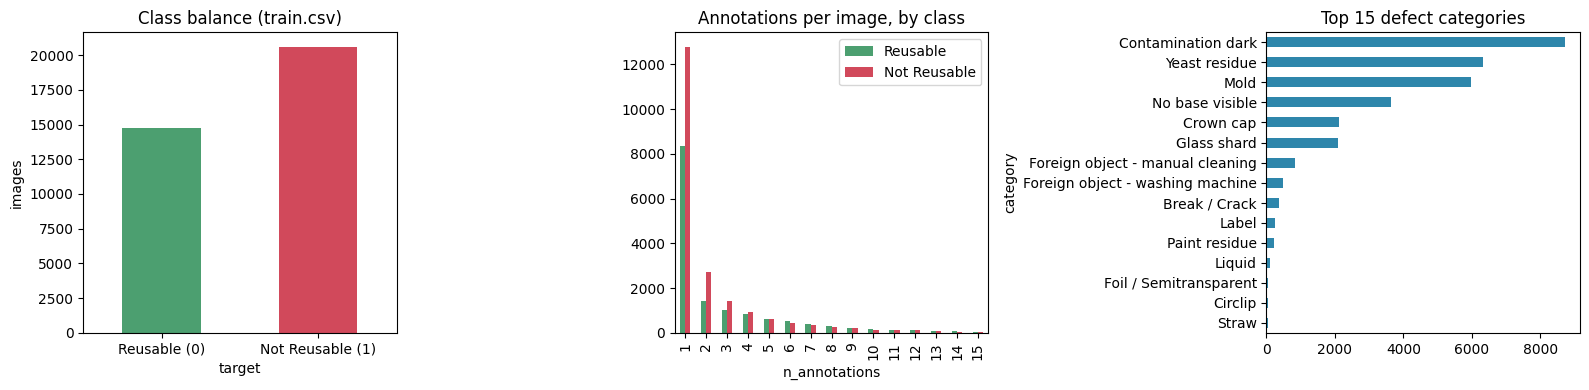

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) Class balance
audit["target"].value_counts().sort_index().plot.bar(
    ax=axes[0], color=["#4C9F70", "#D1495B"]
)
axes[0].set_title("Class balance (train.csv)")
axes[0].set_xticklabels(["Reusable (0)", "Not Reusable (1)"], rotation=0)
axes[0].set_ylabel("images")

# (b) Annotations per image, stratified by target
ann_pivot = (
    audit.groupby(["target", "n_annotations"]).size().unstack("target").fillna(0)
)
ann_pivot.head(15).plot.bar(ax=axes[1], color=["#4C9F70", "#D1495B"], stacked=False)
axes[1].set_title("Annotations per image, by class")
axes[1].set_xlabel("n_annotations")
axes[1].legend(["Reusable", "Not Reusable"])

# (c) Defect-category frequency (top 15)
cat_stats.query("group != 'good'").head(15).plot.barh(
    x="category", y="count", ax=axes[2], color="#2E86AB", legend=False
)
axes[2].set_title("Top 15 defect categories")
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig(OUT_DIR / "eda_overview.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Summary — what this notebook produced

Files in `./artifacts/`:

| File | Used by |
|---|---|
| `train_enriched.csv` | every later notebook — has target, derived_target, session_uuid, size_bucket, fold |
| `splits/fold_{0..4}.csv` | training loop — load fold 0 for primary val, the rest for k-fold CV |
| `label_noise_candidates.csv` | manual review, then optional cleaning/weighting |
| `category_stats.csv` | loss weighting, augmentation targeting |
| `eda_overview.png` | presentation slide |

### What to do next (before training)
1. Open ~50 rows from `label_noise_candidates.csv` (top of the list) in a viewer and note your estimate of the mislabel rate.
2. If the bottle-type proxy (size bucket) doesn't have ~3 dominant values, revisit section 8 — you may need a different proxy.
3. Lock `fold_0.csv` as the canonical val set. Every F1 number you report through the competition should come from this split.